In [1]:
# New Project - US Equities Performance & Risk Analytics

In [2]:
import requests
import pandas as pd
import time
from bs4 import BeautifulSoup

In [3]:
# Tickers - Companies: Apple, Microsoft, Google, Amazon and JP Morgan

tickers = ["AAPL", "MSFT", "GOOGL", "AMZN", "JPM"]

headers = {"User-Agent": "Mozilla/5.0"}

columns = [
    "Date", "Open", "High", "Low",
    "Close", "Adj_Close", "Volume", "Ticker"
]

raw_records = []

In [4]:
for ticker in tickers:
    url = f"https://finance.yahoo.com/quote/{ticker}/history/"

    response = requests.get(
        url, headers=headers, timeout=30
    )
    response.raise_for_status()

In [5]:
    soup = BeautifulSoup(response.text, "html.parser")
    table = soup.find("table")

In [6]:
 for ticker in tickers:
    #  code to request and parse the webpage goes here
    table = soup.find("table")

    if table is None:
        print(f"No HTML table found for {ticker}")
        continue
        ticker_count = 0

In [7]:
for ticker in tickers:
    ticker_count = 0

    # Your existing webpage request and table extraction code

    for row in table.find_all("tr"):
        cells = row.find_all("td")

        if len(cells) != 7:
            continue

        values = [
            cell.get_text(" ", strip=True)
            for cell in cells
        ]
 # Keep genuine daily price records only
        try:
            pd.to_datetime(values[0], format="%b %d, %Y")
        except (ValueError, TypeError):
            continue

        raw_records.append(values + [ticker])
        ticker_count += 1

    print(f"{ticker}: {ticker_count} rows scraped")
    time.sleep(2)

AAPL: 252 rows scraped
MSFT: 252 rows scraped
GOOGL: 252 rows scraped
AMZN: 252 rows scraped
JPM: 252 rows scraped


In [8]:
# Create raw DataFrame without calculated columns
raw_df = pd.DataFrame(raw_records, columns=columns)

In [9]:
raw_df.to_csv(r"C:\Users\Samson\Downloads\Stock_Raw_Data.csv", index=False)

In [10]:
print("\nRaw dataset shape:", raw_df.shape)
print(raw_df.head())
print("\nSaved: Stock_Raw_Data.csv")


Raw dataset shape: (1260, 8)
           Date    Open    High     Low   Close Adj_Close     Volume Ticker
0  Oct 28, 2026  337.38  340.59  335.18  340.42    340.42  1,786,022   AAPL
1  Oct 27, 2026  337.04  337.51  334.50  335.79    335.79  4,711,400   AAPL
2  Oct 26, 2026  334.00  336.49  333.16  334.04    334.04  6,226,500   AAPL
3  Oct 23, 2026  333.00  335.14  330.40  331.58    331.58  4,779,500   AAPL
4  Oct 22, 2026  332.28  336.62  332.26  336.54    336.54  6,199,100   AAPL

Saved: Stock_Raw_Data.csv


In [11]:

import pandas as pd

# Load raw scraped data
clean_df = pd.read_csv(r"C:\Users\Samson\Downloads\Stock_Raw_Data.csv")

print("Original shape:", clean_df.shape)

Original shape: (1260, 8)


In [12]:
# Remove whitespace from text fields
clean_df["Date"] = clean_df["Date"].astype(str).str.strip()
clean_df["Ticker"] = clean_df["Ticker"].astype(str).str.strip()

In [13]:
# Convert dates
clean_df["Date"] = pd.to_datetime(
    clean_df["Date"], format="%b %d, %Y", errors="coerce"
)

In [14]:
# Convert numeric columns
numeric_cols = [
    "Open", "High", "Low", "Close",
    "Adj_Close", "Volume"
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

In [15]:
# Check missing values before removing invalid records
print("\nMissing values before cleaning:")
print(clean_df.isnull().sum())


Missing values before cleaning:
Date         0
Open         0
High         0
Low          0
Close        0
Adj_Close    0
Volume       0
Ticker       0
dtype: int64


In [16]:
# Remove rows missing essential fields
clean_df = clean_df.dropna(
    subset=["Date", "Ticker", "Open", "High", "Low", "Close", "Volume"]
)

# Remove duplicate company-date observations
clean_df = clean_df.drop_duplicates(
    subset=["Ticker", "Date"], keep="first"
)

In [17]:
# Check basic price consistency
invalid_prices = (
    (clean_df["Open"] <= 0) |
    (clean_df["High"] <= 0) |
    (clean_df["Low"] <= 0) |
    (clean_df["Close"] <= 0) |
    (clean_df["High"] < clean_df["Low"]) |
    (clean_df["High"] < clean_df["Open"]) |
    (clean_df["High"] < clean_df["Close"]) |
    (clean_df["Low"] > clean_df["Open"]) |
    (clean_df["Low"] > clean_df["Close"]) |
    (clean_df["Volume"] < 0)
)

print("\nInvalid price rows:", invalid_prices.sum())


Invalid price rows: 0


In [18]:
# Review invalid rows before deciding whether to exclude them
print(clean_df.loc[invalid_prices].head())

Empty DataFrame
Columns: [Date, Open, High, Low, Close, Adj_Close, Volume, Ticker]
Index: []


In [19]:
# Sort chronologically within each ticker
clean_df = clean_df.sort_values(
    ["Ticker", "Date"]
).reset_index(drop=True)

In [20]:
print("\nCleaned shape:", clean_df.shape)
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())


Cleaned shape: (1260, 8)

Missing values after cleaning:
Date         0
Open         0
High         0
Low          0
Close        0
Adj_Close    0
Volume       0
Ticker       0
dtype: int64


In [21]:
print("\nRows per ticker:")
print(clean_df.groupby("Ticker").size())


Rows per ticker:
Ticker
AAPL     252
AMZN     252
GOOGL    252
JPM      252
MSFT     252
dtype: int64


In [22]:
# Work on a separate DataFrame with calculated columns
analysis_df = clean_df.copy()

In [23]:
# Price change from previous trading observation for each ticker
analysis_df["Price_Change"] = (
    analysis_df.groupby("Ticker")["Close"].diff()
)

In [24]:
# Daily percentage return
analysis_df["Daily_Return_Pct"] = (
    analysis_df.groupby("Ticker")["Close"].pct_change() * 100
)

In [25]:
# Daily high-low trading range
analysis_df["Daily_Range"] = (
    analysis_df["High"] - analysis_df["Low"]
)

In [26]:
# Trading range as a percentage of closing price
analysis_df["Range_Pct"] = (
    analysis_df["Daily_Range"] /
    analysis_df["Close"] * 100
)

In [27]:
# Rolling standard deviation of daily returns over 20 observations
analysis_df["20_Day_Volatility_Pct"] = (
    analysis_df.groupby("Ticker")["Daily_Return_Pct"]
    .transform(lambda x: x.rolling(window=20, min_periods=20).std())
)

In [28]:
print("Calculated dataset shape:", analysis_df.shape)
print(analysis_df.head(10))

Calculated dataset shape: (1260, 13)
        Date    Open    High     Low   Close  Adj_Close   Volume Ticker  \
0 2025-10-28  304.86  307.97  303.16  305.36     299.59  6336000   AAPL   
1 2025-10-29  303.51  308.25  303.01  305.51     299.74  7520300   AAPL   
2 2025-10-30  305.79  312.61  305.10  309.44     303.59  7514600   AAPL   
3 2025-10-31  308.54  312.87  307.25  311.12     305.24  7721300   AAPL   
4 2025-11-03  311.00  312.32  306.21  309.35     303.50  7770000   AAPL   
5 2025-11-04  306.71  312.22  305.10  309.25     303.41  7085200   AAPL   
6 2025-11-05  309.61  313.10  305.63  311.68     305.79  6865200   AAPL   
7 2025-11-06  310.99  314.84  310.26  313.42     307.50  7206100   AAPL   
8 2025-11-07  311.89  314.43  307.64  314.21     308.27  7302300   AAPL   
9 2025-11-10  315.00  319.56  314.21  316.89     310.90  5794100   AAPL   

   Price_Change  Daily_Return_Pct  Daily_Range  Range_Pct  \
0           NaN               NaN         4.81   1.575190   
1          0.15

In [29]:
# Save cleaned original data
clean_df.to_csv(r"C:\Users\Samson\Downloads\Stock_Cleaned_Data.csv", index=False)

In [30]:
# Save data with calculated financial indicators
analysis_df.to_csv(r"C:\Users\Samson\Downloads\Stock_Financial_Analysis.csv", index=False)

In [31]:
print("Raw data shape:", raw_df.shape)
print("Cleaned data shape:", clean_df.shape)
print("Financial analysis shape:", analysis_df.shape)

Raw data shape: (1260, 8)
Cleaned data shape: (1260, 8)
Financial analysis shape: (1260, 13)


In [32]:
print("\nFiles saved successfully:")
print("1. Stock_Raw_Data.csv")
print("2. Stock_Cleaned_Data.csv")
print("3. Stock_Financial_Analysis.csv")


Files saved successfully:
1. Stock_Raw_Data.csv
2. Stock_Cleaned_Data.csv
3. Stock_Financial_Analysis.csv


In [33]:
import os

# Create a folder for all visualisations
visuals_folder = "Stock_Financial_Analysis_Virtuals"

os.makedirs(visuals_folder, exist_ok=True)

print("Folder created at:", os.path.abspath(visuals_folder))

Folder created at: C:\Users\Samson\Stock_Financial_Analysis_Virtuals


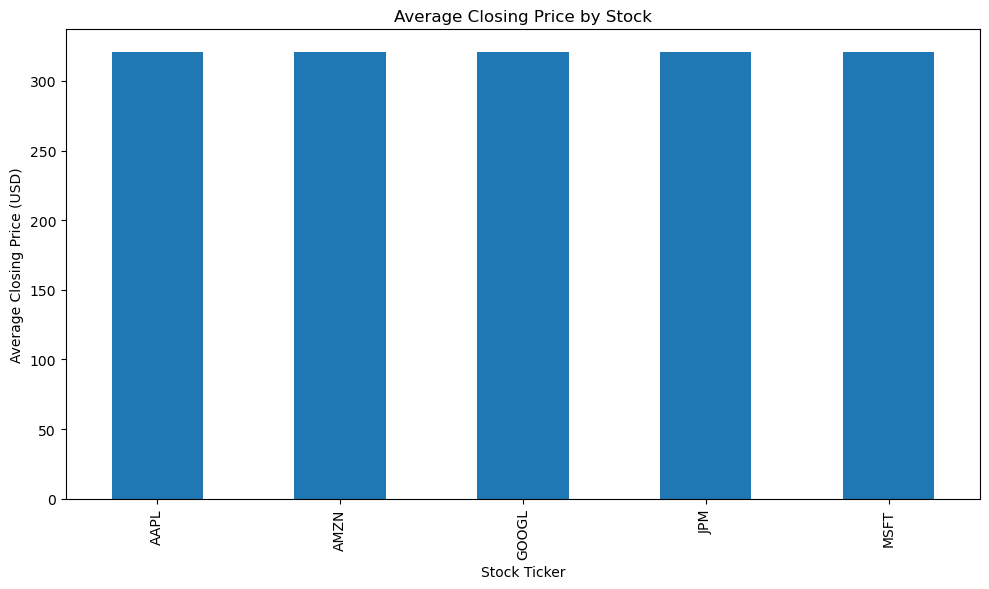

In [34]:
# Visualization
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Visual 1. Bar chart: average closing price by ticker
plt.figure(figsize=(10, 6))

analysis_df.groupby("Ticker")["Close"].mean().plot(
    kind="bar",
    title="Average Closing Price by Stock"
)

plt.xlabel("Stock Ticker")
plt.ylabel("Average Closing Price (USD)")
plt.tight_layout()

plt.savefig(
    os.path.join(visuals_folder, "01_Average_Closing_Price.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

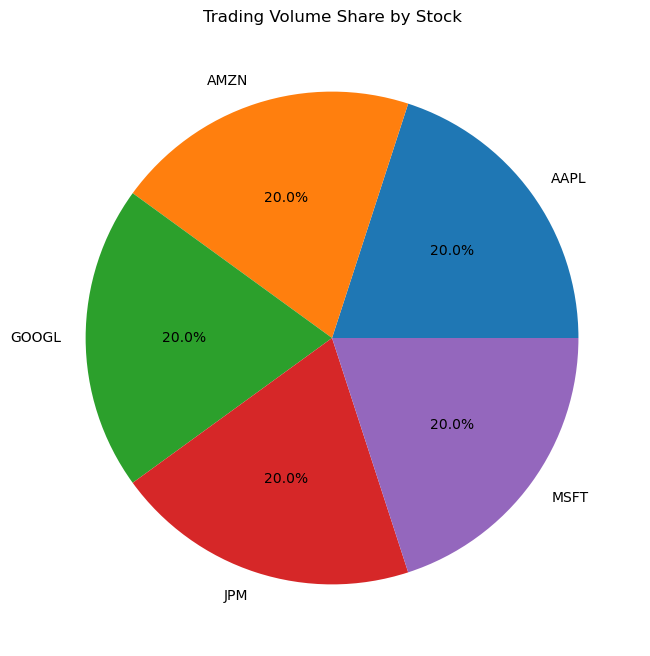

In [35]:
# Visual 2. Pie chart: share of total trading volume
plt.figure(figsize=(8, 8))

analysis_df.groupby("Ticker")["Volume"].sum().plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Trading Volume Share by Stock"
)

plt.ylabel("")

plt.savefig(
    os.path.join(visuals_folder, "02_Trading_Volume_Share.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

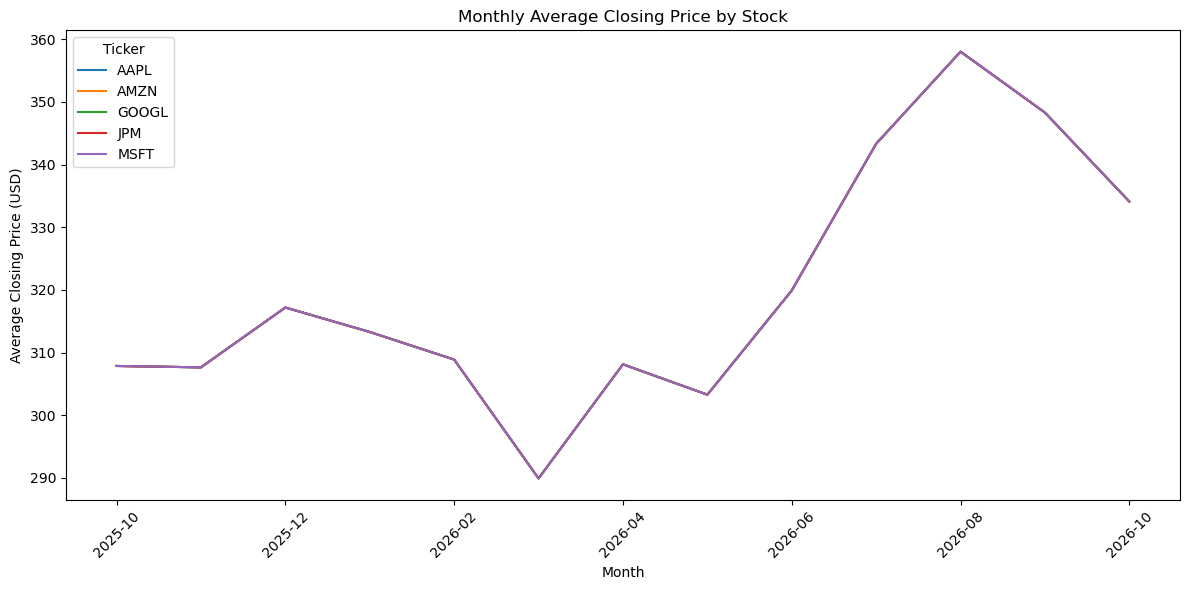

In [36]:
# Visual 3. Column chart: monthly average closing price
monthly_plot = analysis_df.copy()
monthly_plot["Month"] = monthly_plot["Date"].dt.to_period("M").astype(str)

monthly_close = monthly_plot.groupby(
    ["Month", "Ticker"]
)["Close"].mean().unstack()

ax = monthly_close.plot(
    figsize=(12, 6),
    title="Monthly Average Closing Price by Stock"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Closing Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(visuals_folder, "03_Monthly_Closing_Price.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

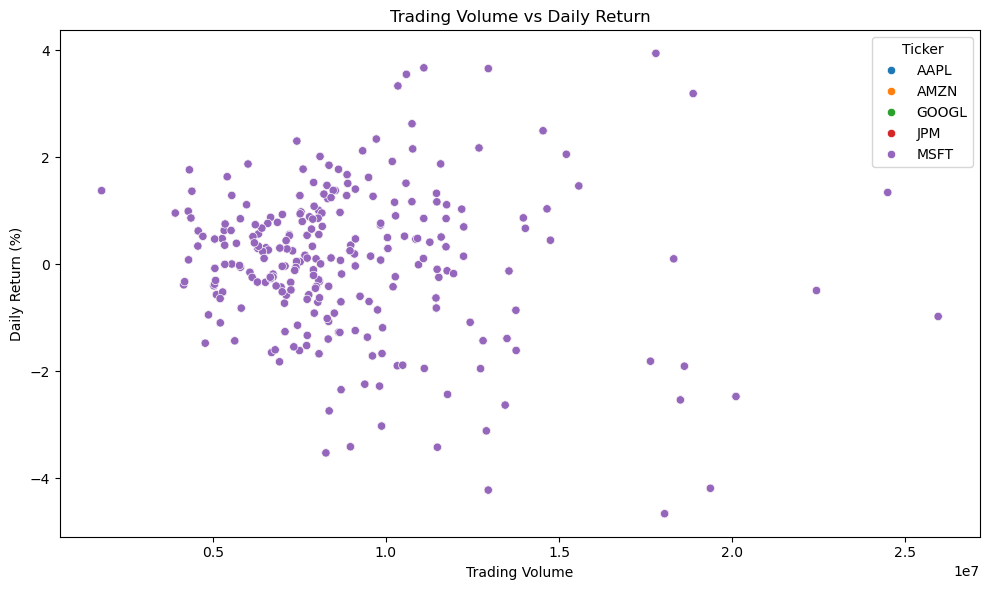

In [37]:
# Visual 4. Scatter plot: trading volume versus daily return
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x="Volume",
    y="Daily_Return_Pct",
    hue="Ticker"
)

plt.title("Trading Volume vs Daily Return")
plt.xlabel("Trading Volume")
plt.ylabel("Daily Return (%)")
plt.tight_layout()

plt.savefig(
    os.path.join(visuals_folder, "04_Volume_vs_Daily_Return.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

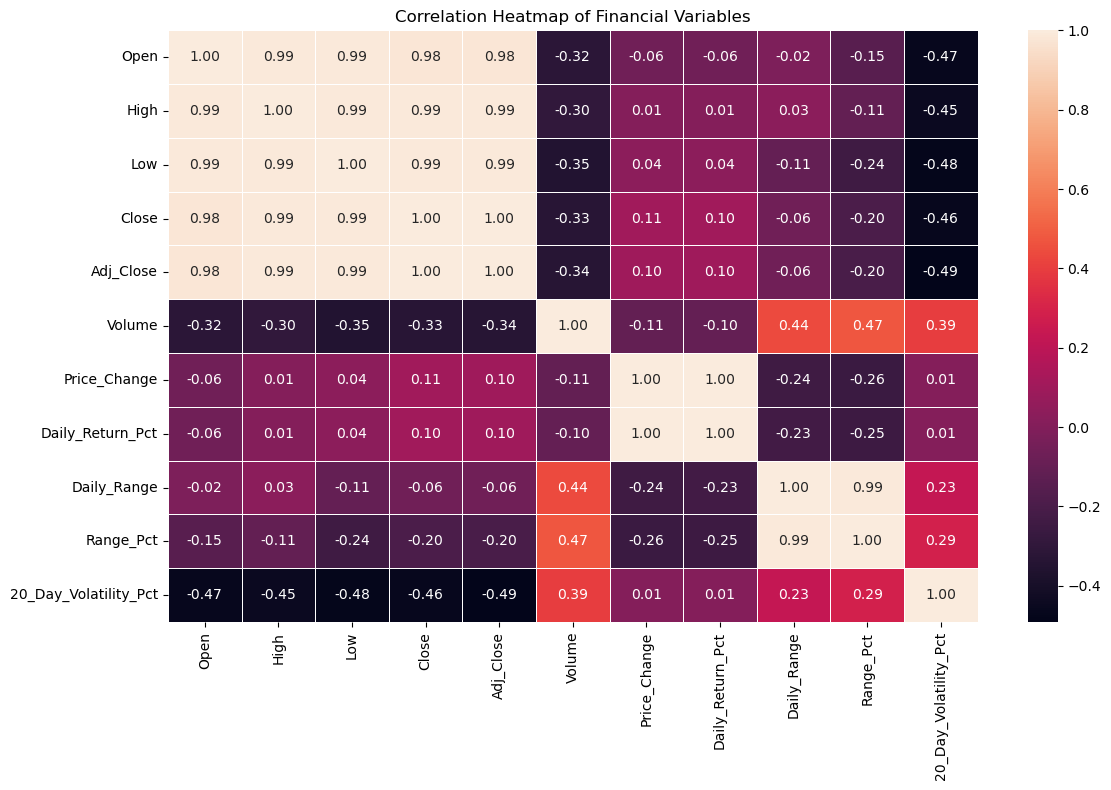

In [38]:
# Visual 5. Correlation heatmap
corr_cols = [
    "Open", "High", "Low", "Close", "Adj_Close",
    "Volume", "Price_Change", "Daily_Return_Pct",
    "Daily_Range", "Range_Pct", "20_Day_Volatility_Pct"
]

correlation_matrix = analysis_df[corr_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Financial Variables")
plt.tight_layout()

plt.savefig(
    os.path.join(visuals_folder, "05_Correlation_Heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

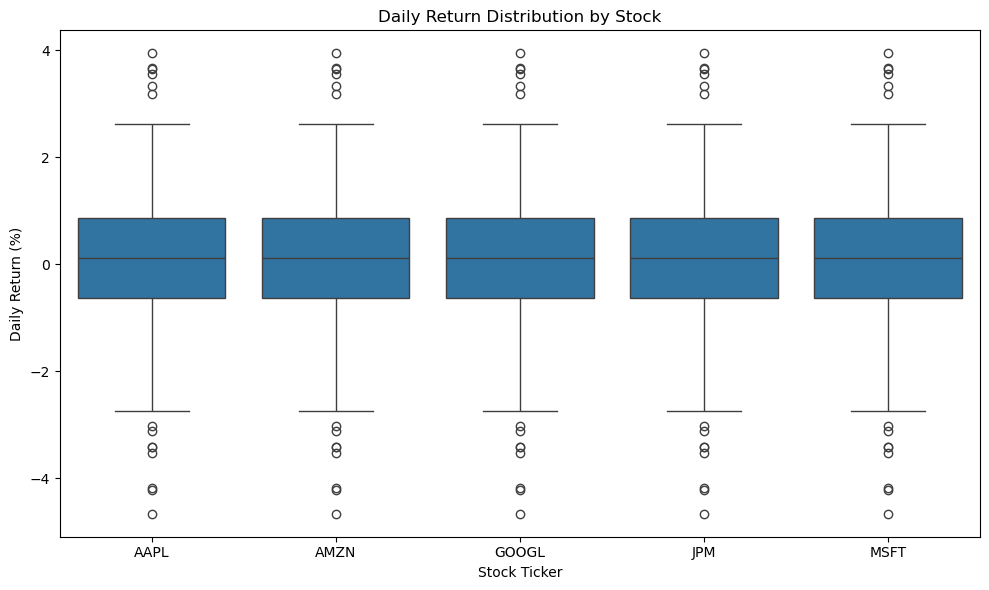

In [39]:
# Visual 6: Box plot of daily returns by company
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x="Ticker",
    y="Daily_Return_Pct"
)

plt.title("Daily Return Distribution by Stock")
plt.xlabel("Stock Ticker")
plt.ylabel("Daily Return (%)")
plt.tight_layout()

plt.savefig(
    os.path.join(visuals_folder, "06_Daily_Return_Boxplot.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

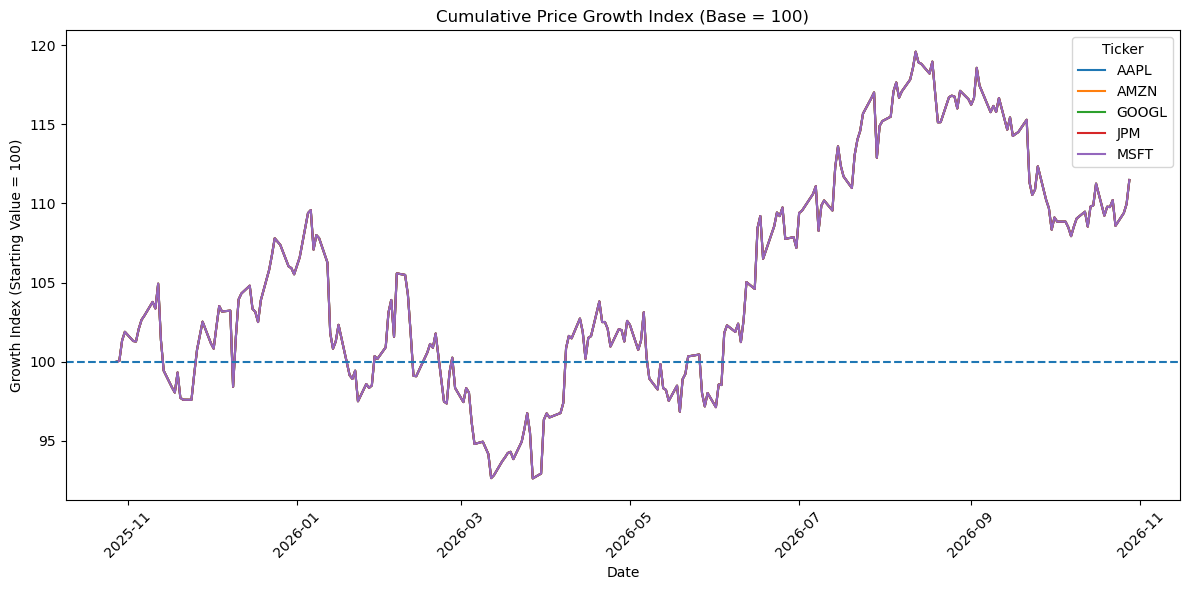

In [40]:

# Visual 7: Cumulative growth index by company

plot_df = analysis_df.sort_values(
    ["Ticker", "Date"]
).copy()

# Calculate daily returns from closing prices
plot_df["Return"] = (
    plot_df.groupby("Ticker")["Close"].pct_change()
)

# Set each stock's index to 100 at the beginning
plot_df["Growth_Index"] = (
    plot_df.groupby("Ticker")["Return"]
    .transform(lambda x: (1 + x.fillna(0)).cumprod() * 100)
)

plt.figure(figsize=(12, 6))

for ticker, group in plot_df.groupby("Ticker"):
    plt.plot(
        group["Date"],
        group["Growth_Index"],
        label=ticker
    )

plt.axhline(100, linestyle="--")
plt.title("Cumulative Price Growth Index (Base = 100)")
plt.xlabel("Date")
plt.ylabel("Growth Index (Starting Value = 100)")
plt.legend(title="Ticker")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(visuals_folder, "07_Cumulative_Growth_Index.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [41]:
print("Saved visualisations:")

for file in sorted(os.listdir(visuals_folder)):
    print(file)

print("\nTotal files:", len(os.listdir(visuals_folder)))
print("Folder location:", os.path.abspath(visuals_folder))

Saved visualisations:
01_Average_Closing_Price.png
02_Trading_Volume_Share.png
03_Monthly_Closing_Price.png
04_Volume_vs_Daily_Return.png
05_Correlation_Heatmap.png
06_Daily_Return_Boxplot.png
07_Cumulative_Growth_Index.png
Company_Performance_Summary.csv
Correlation_Matrix.csv
Correlation_Pairs.csv
Monthly_Trends_Summary.csv
Outlier_Details.csv
Outlier_Summary.csv
Summary_Statistics.csv
Trading_Day_Direction_By_Company.csv

Total files: 15
Folder location: C:\Users\Samson\Stock_Financial_Analysis_Virtuals


In [42]:
import pandas as pd
import numpy as np

numeric_cols = [
    "Open", "High", "Low", "Close", "Adj_Close",
    "Volume", "Price_Change", "Daily_Return_Pct",
    "Daily_Range", "Range_Pct", "20_Day_Volatility_Pct"
]

In [43]:
# Descriptive statistics
summary_stats = analysis_df[numeric_cols].describe().T

summary_stats["Median"] = analysis_df[numeric_cols].median()
summary_stats["Mode"] = analysis_df[numeric_cols].mode().iloc[0]
summary_stats["Variance"] = analysis_df[numeric_cols].var()
summary_stats["Skewness"] = analysis_df[numeric_cols].skew()

print("KEY SUMMARY STATISTICS")
print(summary_stats.round(3))

KEY SUMMARY STATISTICS
                        count         mean          std          min  \
Open                   1260.0      321.060       21.441      282.830   
High                   1260.0      324.218       21.144      283.880   
Low                    1260.0      317.833       21.254      279.100   
Close                  1260.0      320.984       21.131      282.840   
Adj_Close              1260.0      317.651       22.176      278.750   
Volume                 1260.0  8994437.389  3532554.141  1786022.000   
Price_Change           1255.0        0.140        4.404      -14.700   
Daily_Return_Pct       1255.0        0.053        1.384       -4.664   
Daily_Range            1260.0        6.385        2.810        2.450   
Range_Pct              1260.0        2.001        0.900        0.758   
20_Day_Volatility_Pct  1160.0        1.391        0.276        0.801   

                               25%          50%           75%           max  \
Open                       304.86

In [44]:
# Save results to CSV
summary_file = os.path.join(
    visuals_folder,
    "Summary_Statistics.csv"
)

summary_stats.round(3).to_csv(summary_file)

print("\nSummary statistics saved to:")
print(os.path.abspath(summary_file))


Summary statistics saved to:
C:\Users\Samson\Stock_Financial_Analysis_Virtuals\Summary_Statistics.csv


In [45]:
# Correlations between numerical columns

correlation_matrix = analysis_df[numeric_cols].corr(
    method="pearson"
)

print("CORRELATION MATRIX")
print(correlation_matrix.round(3))

# Extract unique pairs, excluding self-correlations
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape), k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle.stack()
    .rename("Correlation")
    .reset_index()
)

correlation_pairs.columns = [
    "Variable_1", "Variable_2", "Correlation"
]

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute_Correlation", ascending=False
)

print("\nTOP 15 CORRELATION PAIRS")
print(correlation_pairs.head(15).round(3))

CORRELATION MATRIX
                        Open   High    Low  Close  Adj_Close  Volume  \
Open                   1.000  0.994  0.991  0.981      0.980  -0.318   
High                   0.994  1.000  0.991  0.990      0.989  -0.296   
Low                    0.991  0.991  1.000  0.993      0.992  -0.353   
Close                  0.981  0.990  0.993  1.000      0.998  -0.333   
Adj_Close              0.980  0.989  0.992  0.998      1.000  -0.337   
Volume                -0.318 -0.296 -0.353 -0.333     -0.337   1.000   
Price_Change          -0.061  0.006  0.038  0.107      0.101  -0.107   
Daily_Return_Pct      -0.061  0.005  0.036  0.105      0.099  -0.101   
Daily_Range           -0.016  0.027 -0.105 -0.060     -0.063   0.437   
Range_Pct             -0.151 -0.111 -0.241 -0.199     -0.201   0.471   
20_Day_Volatility_Pct -0.468 -0.450 -0.478 -0.463     -0.491   0.395   

                       Price_Change  Daily_Return_Pct  Daily_Range  Range_Pct  \
Open                         -0.061

In [46]:
# Save both results to the folder

matrix_file = os.path.join(
    visuals_folder, "Correlation_Matrix.csv"
)

pairs_file = os.path.join(
    visuals_folder, "Correlation_Pairs.csv"
)

correlation_matrix.round(3).to_csv(matrix_file)
correlation_pairs.round(3).to_csv(
    pairs_file, index=False
)

print("\nFiles saved successfully:")
print(os.path.abspath(matrix_file))
print(os.path.abspath(pairs_file))


Files saved successfully:
C:\Users\Samson\Stock_Financial_Analysis_Virtuals\Correlation_Matrix.csv
C:\Users\Samson\Stock_Financial_Analysis_Virtuals\Correlation_Pairs.csv


In [47]:
# Look for any outliers or anomalies in the data

def detect_outliers(df, column):
    values = df[column].dropna() 

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ].copy()

    return outliers, lower_bound, upper_bound

for column in [
    "Daily_Return_Pct", "Volume", "Daily_Range"
]:
    outliers, lower, upper = detect_outliers(
        analysis_df, column
    )

    print(f"\nOutlier analysis: {column}")
    print(f"Lower bound: {lower:.3f}")
    print(f"Upper bound: {upper:.3f}")
    print(f"Number of outliers: {len(outliers)}")

    print(
        outliers[["Date", "Ticker", column]]
        .sort_values(column)
        .head(10)
    )


Outlier analysis: Daily_Return_Pct
Lower bound: -2.917
Upper bound: 3.157
Number of outliers: 70
           Date Ticker  Daily_Return_Pct
785  2025-12-09    JPM         -4.663558
29   2025-12-09   AAPL         -4.663558
533  2025-12-09  GOOGL         -4.663558
281  2025-12-09   AMZN         -4.663558
1037 2025-12-09   MSFT         -4.663558
331  2026-02-23   AMZN         -4.221500
835  2026-02-23    JPM         -4.221500
583  2026-02-23  GOOGL         -4.221500
79   2026-02-23   AAPL         -4.221500
1087 2026-02-23   MSFT         -4.221500

Outlier analysis: Volume
Lower bound: 1215662.500
Upper bound: 16065362.500
Number of outliers: 60
           Date Ticker    Volume
1173 2026-06-26   MSFT  17640900
921  2026-06-26    JPM  17640900
669  2026-06-26  GOOGL  17640900
165  2026-06-26   AAPL  17640900
417  2026-06-26   AMZN  17640900
573  2026-02-06  GOOGL  17797400
1077 2026-02-06   MSFT  17797400
69   2026-02-06   AAPL  17797400
825  2026-02-06    JPM  17797400
321  2026-02-06   AMZ

In [48]:
# Folder for Outliers analysis outputs

visuals_folder = "Stock_Financial_Analysis_Virtuals"
os.makedirs(visuals_folder, exist_ok=True)

In [49]:
# Columns to check for outliers
outlier_columns = [
    "Daily_Return_Pct",
    "Volume",
    "Daily_Range"
]

all_outliers = []
outlier_summary = []

for column in outlier_columns:

    outliers, lower, upper = detect_outliers(
        analysis_df, column
    )

In [50]:
    print(f"\nOutlier analysis: {column}")
    print(f"Lower bound: {lower:.3f}")
    print(f"Upper bound: {upper:.3f}")
    print(f"Number of outliers: {len(outliers)}")

    print(
        outliers[["Date", "Ticker", column]]
        .sort_values(column)
        .head(10)
    )


Outlier analysis: Daily_Range
Lower bound: 0.316
Upper bound: 11.866
Number of outliers: 65
           Date Ticker  Daily_Range
802  2026-01-05    JPM        12.06
46   2026-01-05   AAPL        12.06
550  2026-01-05  GOOGL        12.06
1054 2026-01-05   MSFT        12.06
298  2026-01-05   AMZN        12.06
30   2025-12-10   AAPL        12.73
534  2025-12-10  GOOGL        12.73
786  2025-12-10    JPM        12.73
1038 2025-12-10   MSFT        12.73
282  2025-12-10   AMZN        12.73


In [51]:
# Store all detected outliers
if not outliers.empty:
        outlier_details = outliers[
            ["Date", "Ticker", column]
        ].copy()

        outlier_details["Variable"] = column
        outlier_details["Lower_Bound"] = lower
        outlier_details["Upper_Bound"] = upper

        outlier_details = outlier_details.rename(
            columns={column: "Observed_Value"}
        )

        all_outliers.append(outlier_details)

In [52]:
# Store summary for each variable
outlier_summary.append({
        "Variable": column,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Number_of_Outliers": len(outliers)
    })

In [53]:
# Combine and save all outlier records
if all_outliers:
    outlier_results = pd.concat(
        all_outliers, ignore_index=True
    )
else:
    outlier_results = pd.DataFrame(
        columns=[
            "Date", "Ticker", "Observed_Value",
            "Variable", "Lower_Bound", "Upper_Bound"
        ]
    )

outlier_results.to_csv(
    os.path.join(
        visuals_folder,
        "Outlier_Details.csv"
    ),
    index=False
)

In [54]:
# Save the summary
outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df.to_csv(
    os.path.join(
        visuals_folder,
        "Outlier_Summary.csv"
    ),
    index=False
)

print("\nOutlier results saved successfully.")
print("Folder:", os.path.abspath(visuals_folder))


Outlier results saved successfully.
Folder: C:\Users\Samson\Stock_Financial_Analysis_Virtuals


In [55]:
# Companies analysis

company_analysis = analysis_df.groupby("Ticker").agg(
    Average_Close=("Close", "mean"),
    Median_Close=("Close", "median"),
    Average_Daily_Return=("Daily_Return_Pct", "mean"),
    Return_Std_Dev=("Daily_Return_Pct", "std"),
    Average_Volume=("Volume", "mean"),
    Total_Volume=("Volume", "sum"),
    Average_Daily_Range=("Daily_Range", "mean")
).round(3)

print("PERFORMANCE BY COMPANY")
print(company_analysis)

PERFORMANCE BY COMPANY
        Average_Close  Median_Close  Average_Daily_Return  Return_Std_Dev  \
Ticker                                                                      
AAPL          320.984        315.01                 0.053           1.386   
AMZN          320.984        315.01                 0.053           1.386   
GOOGL         320.984        315.01                 0.053           1.386   
JPM           320.984        315.01                 0.053           1.386   
MSFT          320.984        315.01                 0.053           1.386   

        Average_Volume  Total_Volume  Average_Daily_Range  
Ticker                                                     
AAPL       8994437.389    2266598222                6.385  
AMZN       8994437.389    2266598222                6.385  
GOOGL      8994437.389    2266598222                6.385  
JPM        8994437.389    2266598222                6.385  
MSFT       8994437.389    2266598222                6.385  


In [56]:
# Save the results to CSV
company_file = os.path.join(
    visuals_folder,
    "Company_Performance_Summary.csv"
)

company_analysis.to_csv(company_file, index=True)

print("\nCompany performance results saved to:")
print(os.path.abspath(company_file))


Company performance results saved to:
C:\Users\Samson\Stock_Financial_Analysis_Virtuals\Company_Performance_Summary.csv


In [57]:
# Monthly Analysis

monthly_analysis = analysis_df.copy()

monthly_analysis["Month"] = (
    monthly_analysis["Date"].dt.to_period("M")
)

monthly_summary = monthly_analysis.groupby(
    ["Month", "Ticker"]
).agg(
    Average_Close=("Close", "mean"),
    Average_Daily_Return=("Daily_Return_Pct", "mean"),
    Average_Volume=("Volume", "mean"),
    Trading_Days=("Date", "count")
).reset_index()

print("MONTHLY TRENDS")
print(monthly_summary.head(20).round(3))

MONTHLY TRENDS
      Month Ticker  Average_Close  Average_Daily_Return  Average_Volume  \
0   2025-10   AAPL        307.858                 0.626    7.273050e+06   
1   2025-10   AMZN        307.858                 0.626    7.273050e+06   
2   2025-10  GOOGL        307.858                 0.626    7.273050e+06   
3   2025-10    JPM        307.858                 0.626    7.273050e+06   
4   2025-10   MSFT        307.858                 0.626    7.273050e+06   
5   2025-11   AAPL        307.636                 0.042    7.906247e+06   
6   2025-11   AMZN        307.636                 0.042    7.906247e+06   
7   2025-11  GOOGL        307.636                 0.042    7.906247e+06   
8   2025-11    JPM        307.636                 0.042    7.906247e+06   
9   2025-11   MSFT        307.636                 0.042    7.906247e+06   
10  2025-12   AAPL        317.184                 0.143    9.618891e+06   
11  2025-12   AMZN        317.184                 0.143    9.618891e+06   
12  2025-1

In [58]:
# Save the first 20 monthly trend records to CSV
monthly_file = os.path.join(
    visuals_folder,
    "Monthly_Trends_Summary.csv"
)

monthly_summary.head(20).round(3).to_csv(monthly_file, index=True)

# Confirm the saved file location
print("\nMonthly trends saved successfully to:")
print(os.path.abspath(monthly_file))


Monthly trends saved successfully to:
C:\Users\Samson\Stock_Financial_Analysis_Virtuals\Monthly_Trends_Summary.csv


In [59]:
#Trading Days analysis

daily_direction = analysis_df.dropna(
    subset=["Daily_Return_Pct"]
).groupby("Ticker").agg(
    Positive_Days=(
        "Daily_Return_Pct", lambda x: (x > 0).sum()
    ),
    Negative_Days=(
        "Daily_Return_Pct", lambda x: (x < 0).sum()
    ),
    Zero_Return_Days=(
        "Daily_Return_Pct", lambda x: (x == 0).sum()
    )
)

daily_direction["Positive_Day_Percentage"] = (
    daily_direction["Positive_Days"] /
    (
        daily_direction["Positive_Days"] +
        daily_direction["Negative_Days"] +
        daily_direction["Zero_Return_Days"]
    ) * 100
)

print("TRADING-DAY DIRECTION BY COMPANY")
print(daily_direction.round(2))

TRADING-DAY DIRECTION BY COMPANY
        Positive_Days  Negative_Days  Zero_Return_Days  \
Ticker                                                   
AAPL              137            113                 1   
AMZN              137            113                 1   
GOOGL             137            113                 1   
JPM               137            113                 1   
MSFT              137            113                 1   

        Positive_Day_Percentage  
Ticker                           
AAPL                      54.58  
AMZN                      54.58  
GOOGL                     54.58  
JPM                       54.58  
MSFT                      54.58  


In [60]:
# Save results to CSV
output_file = os.path.join(
    visuals_folder,
    "Trading_Day_Direction_By_Company.csv"
)

daily_direction.round(2).to_csv(output_file)

print("\nResults saved successfully to:")
print(os.path.abspath(output_file))


Results saved successfully to:
C:\Users\Samson\Stock_Financial_Analysis_Virtuals\Trading_Day_Direction_By_Company.csv
